# 4. The filter's dynamics model

> Set up what the filter linearizes about: a reference spacecraft, an a-priori state and covariance, and the reference trajectory with its state transition matrix.
>
> ⏱ ~10 min &nbsp;·&nbsp; **Prereqs:** [2. Truth: dynamics & propagation](02_truth_dynamics.ipynb) &nbsp;·&nbsp; **Uses:** `outputs/02_truth_dynamics/truth.bsp` &nbsp;·&nbsp; **Next:** [5. The filter's measurement model](05_filter_measurements.ipynb)

The filter never sees the truth. It starts from an a-priori estimate of the state, typically the previous orbit determination solution, propagates a **reference trajectory** from it, and estimates a correction to that reference. This chapter builds the reference and checks the two things the filter relies on: the state transition matrix (STM), which maps deviations along the reference, and the a-priori covariance, which describes the uncertainty of the starting point.

## Setup

The scenario from chapter 1. The truth trajectory from chapter 2 is loaded only to construct a known a-priori error and to evaluate the linearization.

In [1]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import scarabaeus as scb

out = Path("outputs/04_filter_dynamics")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

scb.SpiceManager.clear_kernels()
scb.SpiceManager.load_kernel_from_mkfile("orex_approach.tm")
scb.SpiceManager.load_kernel("outputs/02_truth_dynamics/truth.bsp")    # produced by chapter 2

kg, km, m, sec, minute, day = scb.Units.get_units(["kg", "km", "m", "sec", "min", "day"])
J2000 = scb.Frame("J2000")
sun = scb.CelestialBody.from_constants("SUN")

epochs = scb.EpochArray.interval(scb.SpiceManager.utc2et("2018-06-01T00:00:00"),
                                 scb.SpiceManager.utc2et("2018-06-08T00:00:00"),
                                 dt=scb.ArrayWUnits(30, minute), sys="TDB")

orex = scb.Spacecraft("OREx truth", -64000)
planets = ["MERCURY", "VENUS", "EARTH", "MARS", "JUPITER", "SATURN"]

## 1. The reference spacecraft

The filter writes its reference trajectory to an SPK at every iteration, and the measurement models evaluate observables by querying SPICE for the spacecraft's state. The reference therefore needs a SPICE ID distinct from the truth's (`-64000`). Its physical properties are the filter's *model* of the spacecraft; here they match the truth, so the dynamics are consistent and any estimation error comes from the data.

In [2]:
reference = scb.Spacecraft("OREx reference", -64001, scb.ArrayWUnits(1500.0, kg),
                           scb.ArrayWUnits(11.0, m**2).convert_to(km**2), scb.ArrayWUnits(1.2, None))

## 2. The a-priori state

In operations, the a-priori state comes from a previous solution. Here it is constructed from the truth plus a known error of 10 km and 1 cm/s per axis, so that the estimate can be evaluated later:

In [3]:
x_truth0 = orex.get_state(epochs[0], reference_frame="J2000", origin="SUN")

r_apriori = x_truth0.quantity[:3] + scb.ArrayWUnits([10.0] * 3, km)
v_apriori = x_truth0.quantity[3:] + scb.ArrayWUnits([0.01] * 3, m / sec).convert_to(km / sec)

state = (scb.StateDefinition()
         .position(reference, scb.ArrayWFrame(r_apriori, J2000), estimation="estimated", dynamics="dynamic")
         .velocity(reference, scb.ArrayWFrame(v_apriori, J2000), estimation="estimated", dynamics="dynamic"))
x0_reference = scb.StateArray(epoch=epochs[0], origin=sun, state=state)

The flags, written out explicitly above (they are the defaults for position and velocity), tell the filter how to treat each component:

| Flag | Values | Meaning |
|---|---|---|
| `estimation` | `"estimated"` | the filter solves for a correction to the component |
| | `"considered"` | the component's uncertainty is carried into the covariance, but its value is not updated |
| `dynamics` | `"dynamic"` | the component evolves with the equations of motion (position, velocity, stochastic accelerations) |
| | `"static"` | the component is a constant parameter (scale factors, biases, gravitational parameters) |

### State parameters

Beyond position and velocity, the state can include parameters of the force and measurement models, added with `.param(name, owner, value, ...)`. Names are validated against a fixed vocabulary; the most common ones are:

| Parameter | Owner | Size | Used by |
|---|---|---|---|
| `eta_srp` | spacecraft | 1 | SRP scale factor |
| `range_bias_<suffix>`, `rangerate_bias_<suffix>` | ground station | 1 per pass group | ideal range / range-rate biases |
| `gs_delta_location_ECEF_<suffix>` | ground station | 3 | station location corrections |
| `dv_man`, `dv_man1`, … | spacecraft | 3 | impulsive maneuvers |
| `k_thrust`, `dRA`, `dDEC` | spacecraft | 1 | finite-burn magnitude and pointing |
| `a_fogm`, `beta_fogm` | spacecraft | 3 | first-order Gauss–Markov accelerations |
| `gm`, `cnm_n_m`, `snm_n_m`, `pole_ra`, `pole_dec` | celestial body | 1 | gravity field and pole |
| `A2_yark` | small body | 1 | Yarkovsky acceleration |

For example, an SRP scale factor estimated as a constant (chapter 8 uses this):

In [4]:
example = (scb.StateDefinition()
           .position(reference, scb.ArrayWFrame(r_apriori, J2000))
           .velocity(reference, scb.ArrayWFrame(v_apriori, J2000))
           .param("eta_srp", reference, scb.ArrayWFrame(scb.ArrayWUnits([1.0], None), J2000),
                  estimation="estimated", dynamics="static"))

for component in example.components:
    print(component[:4])

('position', 3, 'estimated', 'dynamic')
('velocity', 3, 'estimated', 'dynamic')
('eta_srp', 1, 'estimated', 'static')


Chapters 5–7 use the six-component state defined above.

→ *Fundamentals: Defining a state*

## 3. The reference trajectory and its STM

The reference is propagated with the same force model as the truth. With `propagate_STM=True` (the default) the variational equations are integrated alongside the state, and the propagator exposes the state transition matrix $\Phi(t_k, t_0)$ at every output epoch as an `(N, 36)` array, row-major:

In [5]:
propagator = scb.Propagator(primary_body=reference, state_vector=x0_reference, tspan=epochs,
                            force_models=scb.ForceModelTranslation(reference, third_bodies=planets, cannonball_SRP=True),
                            propagate_STM=True)
propagator.propagate()

Phi = propagator.STM.quantity.values.reshape(-1, 6, 6)
print("Phi:", Phi.shape)
print("\nPhi(t_f, t0) =")
print(Phi[-1].round(4))


                            Starting propagation...                             


Integrating:   0%|                                                      | 0.00/603000.00 s [00:00<?]

Integrating:   0%|                                                      | 0.00/603000.00 s [00:00<?]

Integrating:   0%|                                              | 0.01/603000.00 s [00:00<150:26:37]

Integrating:   0%|                                                      | 0.00/603000.00 s [00:00<?]

...

Integrating: 100%|█████████████████████████████████████████████| 603000.00/603000.00 s [00:00<00:00]

Integrating: 100%|█████████████████████████████████████████████| 603000.00/603000.00 s [00:00<00:00]

Integrating: 100%|█████████████████████████████████████████████| 603000.00/603000.00 s [00:00<00:00]


 =================== DOP853 integration complete. ==================


Propagation complete.
Phi: (336, 6, 6)

Phi(t_f, t0) =
[[ 9.98500000e-01  3.20000000e-03  1.80000000e-03  6.02672607e+05
   6.26303800e+02  3.58618300e+02]
 [ 3.20000000e-03  1.00280000e+00  3.50000000e-03  6.26343000e+02
   6.03575810e+05  7.00930400e+02]
 [ 1.80000000e-03  3.50000000e-03  9.98700000e-01  3.58640700e+02
   7.00930400e+02  6.02752838e+05]
 [-0.00000000e+00  0.00000000e+00  0.00000000e+00  9.98300000e-01
   3.00000000e-03  1.70000000e-03]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  3.00000000e-03
   1.00290000e+00  3.50000000e-03]
 [ 0.00000000e+00  0.00000000e+00 -0.00000000e+00  1.70000000e-03
   3.50000000e-03  9.98800000e-01]]


Over one week in a weak heliocentric gravity field, $\Phi$ is close to the free-flight matrix: identity on the diagonal blocks and $\Phi_{rv} \approx (t - t_0)\,I$ ≈ 603,000 s, with small off-diagonal coupling from the Sun's gravity gradient. The lower-left block $\Phi_{vr}$ is of order $10^{-9}$ s⁻¹ and rounds to zero at this precision.

The reference trajectory is written to an SPK so that it can be compared with the truth:

In [6]:
scb.Trajectory(state_array=propagator.propagated_state_array).write_to_spk(str(out / "reference.bsp"))
scb.SpiceManager.load_kernel(str(out / "reference.bsp"))

## 4. Validating the linearization

The filter assumes that a deviation from the reference evolves linearly: $\delta x(t) \approx \Phi(t, t_0)\,\delta x_0$. Because the true deviation is known here, the assumption can be checked directly by comparing $\Phi\,\delta x_0$ with the actual difference between the truth and reference trajectories:

max linearization error: 0.42 mm


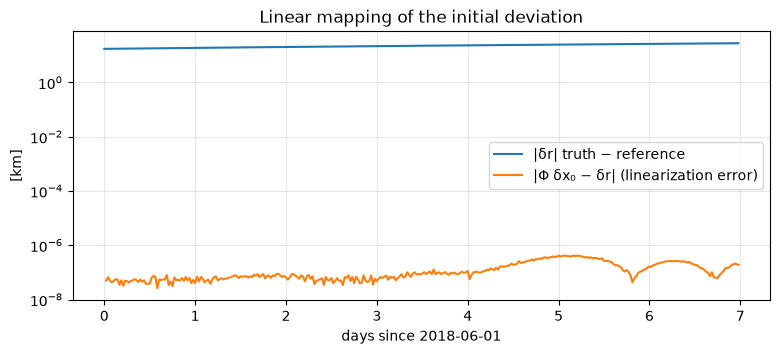

In [7]:
dx0 = (x_truth0.quantity - reference.get_state(epochs[0], reference_frame="J2000", origin="SUN").quantity).values

# TODO(draft): get_state takes one epoch at a time; replace the loop once it accepts an EpochArray
dr_actual, dr_linear_error = [], []
for k, t in enumerate(epochs):
    dx = (orex.get_state(t, reference_frame="J2000", origin="SUN").quantity
          - reference.get_state(t, reference_frame="J2000", origin="SUN").quantity).values
    dx_linear = Phi[k] @ dx0
    dr_actual.append((dx[:3] @ dx[:3]) ** 0.5)
    dr_linear_error.append(((dx_linear - dx)[:3] @ (dx_linear - dx)[:3]) ** 0.5)

days = (epochs - epochs[0]).convert_to(day).values
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogy(days, dr_actual, label="|δr| truth − reference")
ax.semilogy(days[1:], dr_linear_error[1:], label="|Φ δx₀ − δr| (linearization error)")
ax.set(xlabel="days since 2018-06-01", ylabel="[km]", title="Linear mapping of the initial deviation")
ax.legend()
ax.grid(alpha=0.3, which="both")
print(f"max linearization error: {max(dr_linear_error) * 1e6:.2f} mm")

For a 17 km initial error the linear mapping holds to well under a millimeter over the whole week; the floor of a few hundredths of a millimeter is set by the integration and SPK interpolation precision rather than by the linearization, so a single pass of a linearized filter would already be nearly exact. With larger errors, longer arcs or stronger nonlinearity (e.g. close approaches), the neglected second-order terms matter. The filters therefore iterate: they re-linearize about the corrected trajectory and solve again until the correction is negligible. Chapter 6 runs this loop with `fit()`.

## 5. The a-priori covariance

The a-priori covariance $P_0$ describes the uncertainty of the a-priori state. `CovarianceMatrix` accepts a list of standard deviations with units and an epoch; the values below (100 km, 0.1 m/s per axis) are deliberately loose so that the solution is driven by the data:

In [8]:
P0 = scb.CovarianceMatrix([scb.ArrayWUnits(100.0, km)] * 3 + [scb.ArrayWUnits(0.1, m / sec).convert_to(km / sec)] * 3,
                          epochs[0], from_list=True)
print("1σ:", P0.get_standard_deviations())

1σ: [1.e+02 1.e+02 1.e+02 1.e-04 1.e-04 1.e-04]


Without measurements, the covariance evolves as $P(t) = \Phi(t, t_0)\,P_0\,\Phi(t, t_0)^T$. Mapping $P_0$ over the arc shows how the uncertainty would grow if no tracking were available:

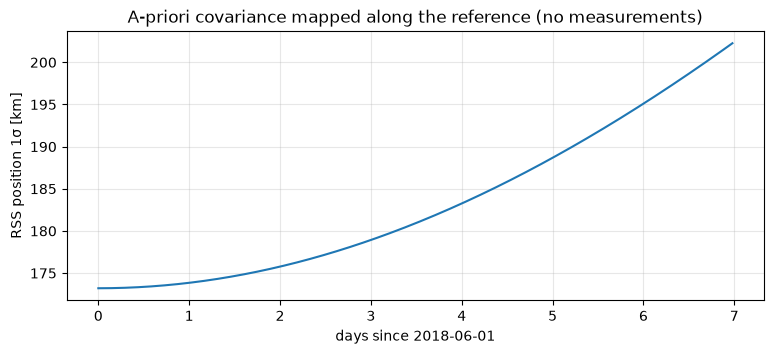

In [9]:
P0_values = P0.to_array()
sigma_r = [((Phi[k] @ P0_values @ Phi[k].T).diagonal()[:3].sum()) ** 0.5 for k in range(epochs.size)]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(days, sigma_r)
ax.set(xlabel="days since 2018-06-01", ylabel="RSS position 1σ [km]", title="A-priori covariance mapped along the reference (no measurements)")
ax.grid(alpha=0.3)

The velocity uncertainty (0.1 m/s per axis) adds about 60 km per axis over the week, so the position uncertainty grows from 173 km to about 200 km (RSS). Chapter 6 shows how the tracking data collapses it.

## Summary

| Concept | Scarabaeus API |
|---|---|
| Reference spacecraft | `Spacecraft` with its own SPICE ID |
| A-priori state | `StateDefinition` with `estimation` / `dynamics` flags, `StateArray` |
| Additional parameters | `StateDefinition.param(name, owner, value, estimation=..., dynamics=...)` |
| Reference trajectory and STM | `Propagator(..., propagate_STM=True)`, `Propagator.STM` |
| A-priori covariance | `CovarianceMatrix([...sigmas...], epoch, from_list=True)`, `get_standard_deviations`, `to_array` |

The filters construct and propagate the reference themselves from the `Propagator` passed to them; chapter 6 passes exactly this setup.

**Next:** [5. The filter's measurement model](05_filter_measurements.ipynb) evaluates the tracking data against this reference: pre-fit residuals, measurement partials, and the linearized measurement equation.